<a href="https://colab.research.google.com/github/mj-creates/Active-Learning-ML/blob/main/01_data_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install datasets scikit-learn pandas matplotlib

In [4]:
from datasets import load_dataset
import numpy as np

# ---------- TREC loader (tries 3 ways, because the old script format is blocked) ----------
def _load_trec():
    attempts = [
        lambda: load_dataset("CogComp/trec", revision="refs/convert/parquet"),
        lambda: load_dataset("parquet", data_files={
            "train": "hf://datasets/CogComp/trec@refs%2Fconvert%2Fparquet/default/train/0000.parquet",
            "test":  "hf://datasets/CogComp/trec@refs%2Fconvert%2Fparquet/default/test/0000.parquet"}),
        lambda: load_dataset("trec", revision="refs/convert/parquet"),
    ]
    last = None
    for a in attempts:
        try:
            return a()
        except Exception as e:
            last = e
    raise RuntimeError(f"All TREC loading methods failed: {last}")


# ---------- one registry: name -> (loader, text column, label column) ----------
DATASETS = {
    "ag_news": (lambda: load_dataset("fancyzhx/ag_news"), "text", "label"),
    "trec":    (_load_trec, "text", "coarse_label"),
    "imdb":    (lambda: load_dataset("stanfordnlp/imdb"), "text", "label"),
}


def load_data(name, pool_cap=8000, test_cap=3000, seed=123):
    """Returns train_texts, train_labels, test_texts, test_labels (labels as numpy int arrays)."""
    loader, tcol, lcol = DATASETS[name]
    ds = loader()
    tr, te = ds["train"], ds["test"]
    # safety: if the label column name differs, show what exists
    if lcol not in tr.column_names:
        raise KeyError(f"{name}: '{lcol}' not found. Columns are {tr.column_names}")
    rng = np.random.RandomState(seed)
    ip = rng.choice(len(tr), min(pool_cap, len(tr)), replace=False)
    it = rng.choice(len(te), min(test_cap, len(te)), replace=False)
    train_texts  = [tr[int(i)][tcol] for i in ip]
    train_labels = np.array([tr[int(i)][lcol] for i in ip])
    test_texts   = [te[int(i)][tcol] for i in it]
    test_labels  = np.array([te[int(i)][lcol] for i in it])
    return train_texts, train_labels, test_texts, test_labels


# ---------- check all 3 ----------
if __name__ == "__main__" or True:
    for name in DATASETS:
        xt, yt, xs, ys = load_data(name)
        print(f"{name:8s} | pool={len(xt):5d} test={len(xs):5d} classes={len(set(yt))}")
        print("   sample:", xt[0][:90].replace("\n", " "), "->", yt[0])

ag_news  | pool= 8000 test= 3000 classes=4
   sample: NHL on Ice, Maybe for Whole 2004-05 Season (AP) AP - No shots, no saves, no goals. The Nat -> 1


0000.parquet:   0%|          | 0.00/213k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/17.1k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

imdb     | pool= 8000 test= 3000 classes=2
   sample: After reading some quite negative views for this movie, I was not sure whether I should fo -> 1


In [6]:
import numpy as np, pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

SEEDS = [0, 1, 2]
INIT_SIZE, QUERY_SIZE = 50, 50
ROUNDS = 15
STRATEGIES = ["random", "least_confidence", "margin", "entropy", "qbc"]
QBC_MEMBERS = 5

def make_model():
    return LogisticRegression(max_iter=300, C=5.0)

# ---------- query strategies ----------
def uncertainty_scores(model, X, strategy):
    P = model.predict_proba(X)
    if strategy == "least_confidence":
        return 1.0 - P.max(axis=1)
    if strategy == "margin":
        s = np.sort(P, axis=1)
        return -(s[:, -1] - s[:, -2])
    if strategy == "entropy":
        return -(P * np.log(P + 1e-12)).sum(axis=1)
    raise ValueError(strategy)

def qbc_scores(X_lab, y_lab, X_pool, rng, n_classes):
    votes = np.zeros((X_pool.shape[0], n_classes))
    for _ in range(QBC_MEMBERS):
        idx = rng.choice(len(y_lab), len(y_lab), replace=True)
        if len(np.unique(y_lab[idx])) < 2:
            continue
        pred = make_model().fit(X_lab[idx], y_lab[idx]).predict(X_pool)
        votes[np.arange(len(pred)), pred] += 1
    V = votes / QBC_MEMBERS
    return -(V * np.log(V + 1e-12)).sum(axis=1)

# ---------- the active learning loop ----------
def run_al(Xp, yp, Xt, yt, strategy, seed, name, n_classes):
    rng = np.random.RandomState(seed)
    lab = list(rng.choice(len(yp), INIT_SIZE, replace=False))
    unl = np.setdiff1d(np.arange(len(yp)), lab)
    rows = []
    for r in range(ROUNDS + 1):
        model = make_model().fit(Xp[lab], yp[lab])
        pred = model.predict(Xt)
        acc = accuracy_score(yt, pred)
        f1 = f1_score(yt, pred, average="macro")
        rows.append(dict(dataset=name, model="tfidf_lr", strategy=strategy, seed=seed,
                         n_labelled=len(lab), acc=acc, macro_f1=f1))
        print(f"[{name}|{strategy}] round {r} | labelled={len(lab)} | unlabelled={len(unl)} | acc={acc:.3f}")
        if r == ROUNDS:
            break
        if strategy == "random":
            pick = rng.choice(unl, QUERY_SIZE, replace=False)
        elif strategy == "qbc":
            pick = unl[np.argsort(-qbc_scores(Xp[lab], yp[lab], Xp[unl], rng, n_classes))[:QUERY_SIZE]]
        else:
            pick = unl[np.argsort(-uncertainty_scores(model, Xp[unl], strategy))[:QUERY_SIZE]]
        lab += list(pick)
        unl = np.setdiff1d(unl, pick)
    return rows

# ---------- run on all 3 datasets ----------
all_rows = []
for name in DATASETS:
    xt, yt, xs, ys = load_data(name)
    vec = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), sublinear_tf=True)
    Xp, Xt = vec.fit_transform(xt), vec.transform(xs)
    ncls = len(np.unique(yt))
    for strat in STRATEGIES:
        for sd in SEEDS:
            all_rows += run_al(Xp, yt, Xt, ys, strat, sd, name, ncls)

df = pd.DataFrame(all_rows)
df.to_csv("results_smoke.csv", index=False)
print(df.groupby(["dataset", "strategy"]).acc.last())

[ag_news|random] round 0 | labelled=50 | unlabelled=7950 | acc=0.266
[ag_news|random] round 1 | labelled=100 | unlabelled=7900 | acc=0.505
[ag_news|random] round 2 | labelled=150 | unlabelled=7850 | acc=0.595
[ag_news|random] round 3 | labelled=200 | unlabelled=7800 | acc=0.704
[ag_news|random] round 4 | labelled=250 | unlabelled=7750 | acc=0.724
[ag_news|random] round 5 | labelled=300 | unlabelled=7700 | acc=0.742
[ag_news|random] round 6 | labelled=350 | unlabelled=7650 | acc=0.763
[ag_news|random] round 7 | labelled=400 | unlabelled=7600 | acc=0.758
[ag_news|random] round 8 | labelled=450 | unlabelled=7550 | acc=0.777
[ag_news|random] round 9 | labelled=500 | unlabelled=7500 | acc=0.777
[ag_news|random] round 10 | labelled=550 | unlabelled=7450 | acc=0.788
[ag_news|random] round 11 | labelled=600 | unlabelled=7400 | acc=0.800
[ag_news|random] round 12 | labelled=650 | unlabelled=7350 | acc=0.807
[ag_news|random] round 13 | labelled=700 | unlabelled=7300 | acc=0.804
[ag_news|random] 

                             acc         macro_f1        
                            mean     std     mean     std
dataset strategy                                         
ag_news entropy           0.8318  0.0051   0.8315  0.0053
        least_confidence  0.8330  0.0042   0.8332  0.0045
        margin            0.8320  0.0027   0.8323  0.0029
        qbc               0.8304  0.0064   0.8299  0.0066
        random            0.8203  0.0038   0.8195  0.0047
imdb    entropy           0.8401  0.0076   0.8401  0.0076
        least_confidence  0.8401  0.0076   0.8401  0.0076
        margin            0.8401  0.0076   0.8401  0.0076
        qbc               0.8368  0.0020   0.8366  0.0021
        random            0.8349  0.0032   0.8348  0.0031
trec    entropy           0.7260  0.1008   0.7614  0.0670
        least_confidence  0.7193  0.0690   0.7523  0.0487
        margin            0.8053  0.0264   0.7519  0.0821
        qbc               0.8233  0.0140   0.8141  0.0386
        random

/tmp/ipykernel_744/540669306.py:13: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(g.acc, g.n_labelled) / (g.n_labelled.max() - g.n_labelled.min())
/tmp/ipykernel_744/540669306.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  auc = (df.groupby(["dataset", "strategy", "seed"]).apply(alc)


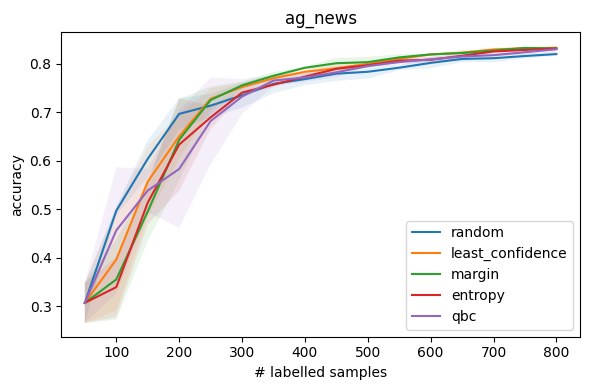

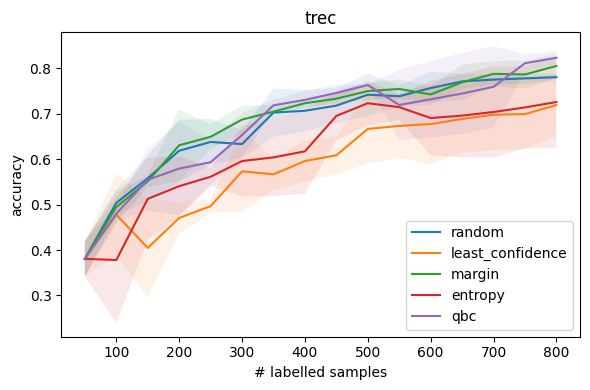

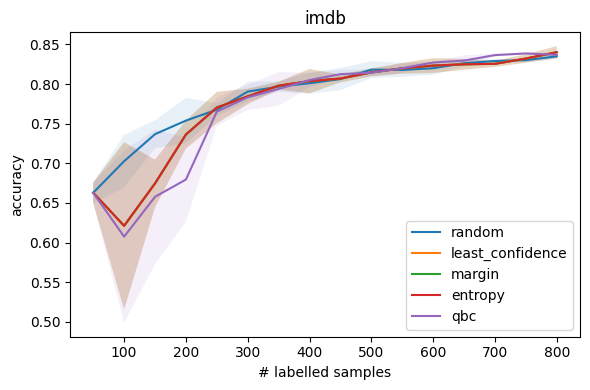

In [7]:
import numpy as np, matplotlib.pyplot as plt

df.to_csv("results_lr.csv", index=False)

# 1) final accuracy: mean ± std over seeds, at the last round
last = df[df.n_labelled == df.n_labelled.max()]
final = last.groupby(["dataset", "strategy"])[["acc", "macro_f1"]].agg(["mean", "std"]).round(4)
print(final)

# 2) area under the learning curve (rewards getting good early), mean over seeds
def alc(g):
    g = g.sort_values("n_labelled")
    return np.trapz(g.acc, g.n_labelled) / (g.n_labelled.max() - g.n_labelled.min())
auc = (df.groupby(["dataset", "strategy", "seed"]).apply(alc)
         .groupby(["dataset", "strategy"]).agg(["mean", "std"]).round(4))
print(auc)
auc.to_csv("auc_lr.csv")

# 3) learning curves, one plot per dataset
for name in df.dataset.unique():
    plt.figure(figsize=(6, 4))
    for s in df.strategy.unique():
        g = df[(df.dataset == name) & (df.strategy == s)].groupby("n_labelled").acc.agg(["mean", "std"])
        plt.plot(g.index, g["mean"], label=s)
        plt.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], alpha=0.1)
    plt.xlabel("# labelled samples"); plt.ylabel("accuracy"); plt.title(name)
    plt.legend(); plt.tight_layout(); plt.savefig(f"curve_{name}.png", dpi=200); plt.show()